In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from torch.utils.data import DataLoader
from tqdm.notebook import tqdm
import random
from torch.utils.data import DataLoader, Subset
from torch import autograd

In [2]:
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(device)


mps


### Загрузка датасета


In [3]:
transform = transforms.Compose([
  transforms.ToTensor(),
  transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])
# Данные для обучения
train_dataset = torchvision.datasets.CIFAR10(root="./cifar",  download=True, train=True, transform=transform)

# Данные для тестирования
val_dataset = torchvision.datasets.CIFAR10(
  root="./cifar", download=True, train=False, transform=transform
)

classes = (
  "plane",
  "car",
  "bird",
  "cat",
  "deer",
  "dog",
  "frog",
  "horse",
  "ship",
  "truck",
)

In [4]:
len(train_dataset), len(val_dataset)

(50000, 10000)

In [5]:
batch_size = 64
trainloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [6]:
trainloader

### Архитектура сетки

Чтобы увидеть влияние dropout, сеть должна быть достаточно мощной, чтобы переобучаться. Я возбму:

- Свёртка 32 → 32, ядро 3, padding=1, ReLU, MaxPool 2×2
- Свёртка 32 → 64, ядро 3, padding=1, ReLU, MaxPool 2×2
- Flatten → Linear(64×8×8=4096, 10) — без дополнительных полносвязных слоёв.

In [7]:
class Mymodel(nn.Module):
  def __init__(self, dropout_prob=0.0):
    super().__init__()
    self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
    self.relu1 = nn.ReLU()
    self.pool1 = nn.MaxPool2d(2)
    self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
    self.relu2 = nn.ReLU()
    self.pool2 = nn.MaxPool2d(2)
    self.flat = nn.Flatten()
    self.drop = nn.Dropout(dropout_prob)
    self.lin = nn.Linear(4096, 10)
  
  def forward(self, x):
    x = self.pool1(self.relu1(self.conv1(x)))
    x = self.pool2(self.relu2(self.conv2(x)))
    x = self.flat(x)
    x = self.drop(x)
    return self.lin(x)


### Обучение 

In [8]:
def train_model(model, trainloader, testloader, criterion, optimizer, device, epochs=30):
  history = {'train_loss_epoch' : [],
             'train_acc_epoch' : [],
             'test_loss_epoch' : [],
             'test_acc_epoch' : []}
  model.train()
  for epoch in range(epochs):
    train_loss_epoch = 0
    train_acc_epoch = 0
    test_loss_epoch = 0
    test_acc_epoch = 0
    
    loop = tqdm(trainloader, desc=f"Epoch {epoch+1}/{epochs}")
    for X_batch, y_batch in loop:
      X_batch = X_batch.to(device)
      y_batch = y_batch.to(device)

      optimizer.zero_grad()
      logits = model(X_batch)
      loss = criterion(logits, y_batch)
      loss.backward()
      optimizer.step()

      train_loss_epoch += loss.item() * X_batch.size(0)
      train_acc_epoch += (y_batch == logits.argmax(dim=-1)).sum().item()

      loop.set_postfix(loss=loss.item())
    
    train_loss_epoch = train_loss_epoch / len(trainloader.dataset)
    train_acc_epoch = train_acc_epoch / len(trainloader.dataset)

    model.eval()
    with torch.no_grad():
      for X_batch, y_batch in testloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)
        logits = model(X_batch)
        loss = criterion(logits, y_batch)

        test_loss_epoch += loss.item() * X_batch.size(0)
        test_acc_epoch += (y_batch == logits.argmax(dim=-1)).sum().item()
      
      test_loss_epoch = test_loss_epoch / len(testloader.dataset)
      test_acc_epoch = test_acc_epoch / len(testloader.dataset)

    model.train()

    history['train_loss_epoch'].append(train_loss_epoch)
    history['train_acc_epoch'].append(train_acc_epoch)
    history['test_loss_epoch'].append(test_loss_epoch)
    history['test_acc_epoch'].append(test_acc_epoch)
    print(f"Epoch {epoch+1}: Train Loss={train_loss_epoch:.4f}, Train Acc={train_acc_epoch:.4f}, Test Loss={test_loss_epoch:.4f}, Test Acc={test_acc_epoch:.4f}")

    
  return history


### Фиксируем одинаковые начальные веса моделей

In [9]:
def set_seed(seed=42):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Перед созданием каждой модели вызываем:
set_seed(42)

### Обучение с разным дропаутом

In [10]:
dropout_probs = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 0.83, 0.86, 0.90, 0.93, 0.96, 1.0]
criterion = nn.CrossEntropyLoss()

for p in dropout_probs:
  print(f"\n===== Обучение модели с dropout = {p} =====")
  set_seed(42)   # Одинаковая инициализация для всех моделей
  model = Mymodel(dropout_prob=p).to(device)
  optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
  history = train_model(model, trainloader, valloader, criterion, optimizer, device, epochs=30)

  # Сохраняем обученные веса
  torch.save(model.state_dict(), f"model_drop{p}.pth")
  print(f"Модель сохранена в model_drop{p}.pth")


===== Обучение модели с dropout = 0.0 =====


Epoch 1/30:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 1: Train Loss=1.3754, Train Acc=0.5151, Test Loss=1.1064, Test Acc=0.6152


Epoch 2/30:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 2: Train Loss=1.0238, Train Acc=0.6434, Test Loss=0.9790, Test Acc=0.6648


...

Epoch 28: Train Loss=2.3027, Train Acc=0.0960, Test Loss=2.3022, Test Acc=0.1002


Epoch 29/30:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 29: Train Loss=2.3027, Train Acc=0.0989, Test Loss=2.3021, Test Acc=0.1006


Epoch 30/30:   0%|          | 0/782 [00:00<?, ?it/s]

Epoch 30: Train Loss=2.3027, Train Acc=0.0962, Test Loss=2.3026, Test Acc=0.0999
Модель сохранена в model_drop1.0.pth


### Визуализация результатов

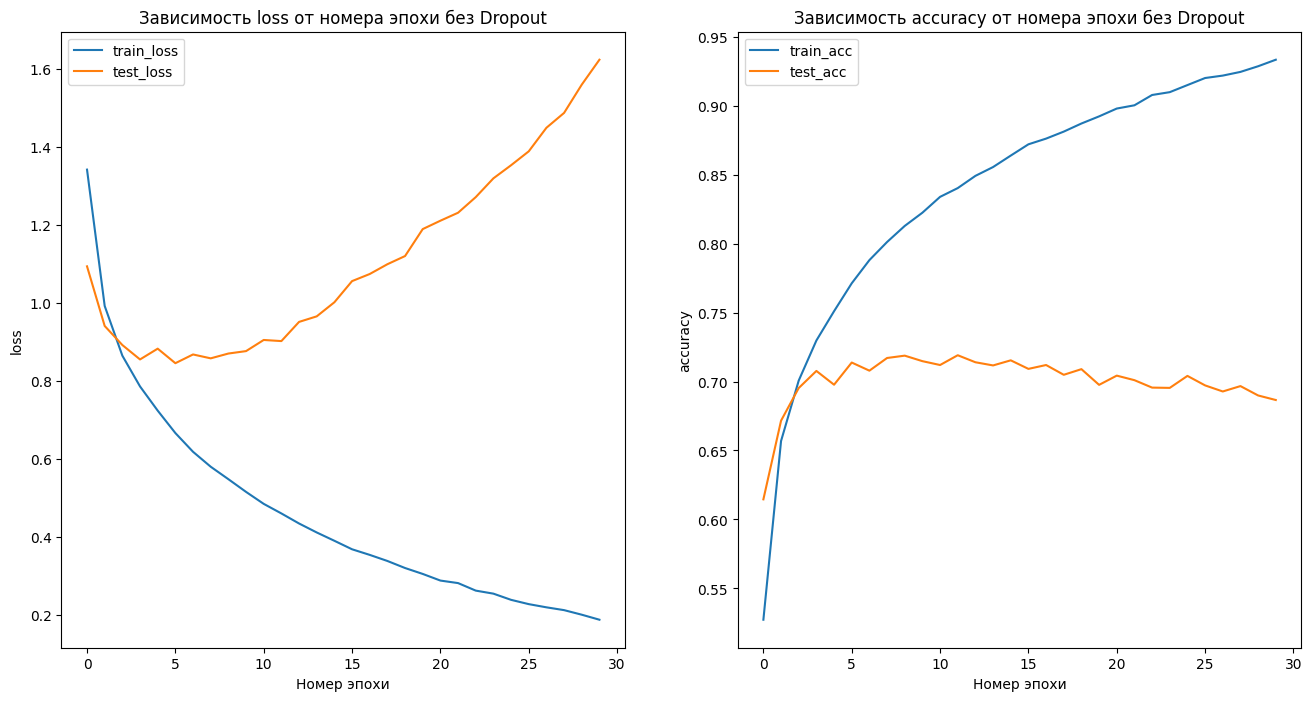

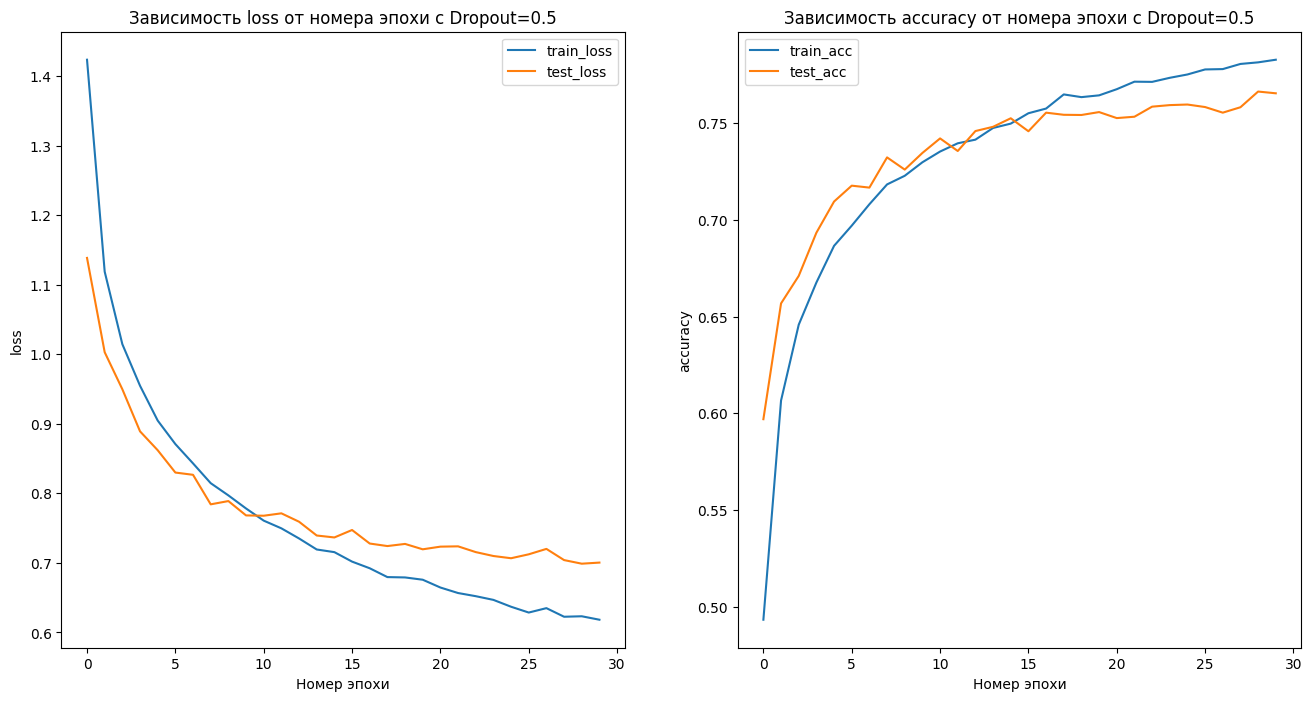

In [18]:
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
X = np.arange(30)
plt.plot(X, nodrop_history['train_loss_epoch'], label='train_loss')
plt.plot(X, nodrop_history['test_loss_epoch'], label='test_loss')
plt.xlabel('Номер эпохи')
plt.ylabel('loss')
plt.title('Зависимость loss от номера эпохи без Dropout')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(X, nodrop_history['train_acc_epoch'], label='train_acc')
plt.plot(X, nodrop_history['test_acc_epoch'], label='test_acc')
plt.xlabel('Номер эпохи')
plt.ylabel('accuracy')
plt.title('Зависимость accuracy от номера эпохи без Dropout')
plt.legend()

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(X, drop_history['train_loss_epoch'], label='train_loss')
plt.plot(X, drop_history['test_loss_epoch'], label='test_loss')
plt.xlabel('Номер эпохи')
plt.ylabel('loss')
plt.title('Зависимость loss от номера эпохи с Dropout=0.5')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(X, drop_history['train_acc_epoch'], label='train_acc')
plt.plot(X, drop_history['test_acc_epoch'], label='test_acc')
plt.xlabel('Номер эпохи')
plt.ylabel('accuracy')
plt.title('Зависимость accuracy от номера эпохи с Dropout=0.5')

plt.legend()
plt.show()

### Вычисление hvp

In [11]:
def hvp(model, loss, params, v):
  grad = autograd.grad(
    loss,
    params,
    create_graph=True,
    retain_graph=True,
    allow_unused=True
  )

  fixed_grad = []
  for g, p in zip(grad, params):
    if g is None:
      fixed_grad.append(torch.zeros_like(p))
    else:
      fixed_grad.append(g)

  grad_vec = torch.cat([g.reshape(-1) for g in fixed_grad])
  grad_v = torch.dot(grad_vec, v)

  Hv = autograd.grad(
    grad_v,
    params,
    retain_graph=False,
    allow_unused=True
  )

  fixed_Hv = []
  for h, p in zip(Hv, params):
    if h is None:
      fixed_Hv.append(torch.zeros_like(p))
    else:
      fixed_Hv.append(h)

  Hv_vec = torch.cat([h.contiguous().reshape(-1) for h in fixed_Hv])
  return Hv_vec.detach()

In [11]:
def hvp(model, loss, params, v):
  """
  Вычисляет произведение гессиана функции потерь loss (на одном объекте)
  на вектор v для заданных params.
  """
  # Шаг 1: получаем градиент функции потерь по выбранным параметрам
  grad = autograd.grad(loss, params, create_graph=True)
    
  # Шаг 2: превращаем список градиентов в один плоский вектор
  grad_vec = torch.cat([g.view(-1) for g in grad])
    
  # Шаг 3: умножаем гессиан на вектор v
  Hv = autograd.grad(grad_vec, params, grad_outputs=v, retain_graph=True)
    
  # Шаг 4: превращаем результат в плоский вектор и возвращаем
  Hv_vec = torch.cat([h.contiguous().view(-1) for h in Hv])
  return Hv_vec

### Степенной метод для спектральной нормы матрицы разности

In [12]:
def h_avg_times_v_sampled(model, avg_loader, selected_params, v, max_batches=1):
  model.eval()
  criterion_sum = nn.CrossEntropyLoss(reduction='sum')

  Hv_sum = torch.zeros_like(v)
  total_count = 0

  for batch_idx, (inputs, targets) in enumerate(avg_loader):
    inputs = inputs.to(device)
    targets = targets.to(device)

    loss = criterion_sum(model(inputs), targets)
    Hv_sum += hvp(model, loss, selected_params, v)
    total_count += inputs.size(0)

    if batch_idx + 1 >= max_batches:
      break

  if total_count == 0:
    return torch.zeros_like(v)

  return Hv_sum / total_count


def spectral_norm_diff(model, inputs, target, avg_loader, selected_params, num_iters=8, avg_max_batches=1, eps=1e-12):
  model.eval()
  criterion_single = nn.CrossEntropyLoss(reduction='sum')

  num_params = sum(p.numel() for p in selected_params)
  v = torch.randn(num_params, device=device)
  v = v / (torch.norm(v) + eps)

  for _ in range(num_iters):
    loss = criterion_single(model(inputs), target)
    Hv_i = hvp(model, loss, selected_params, v)
    H_avg_v = h_avg_times_v_sampled(model, avg_loader, selected_params, v, max_batches=avg_max_batches)
    H_diff_v = Hv_i - H_avg_v

    norm = torch.norm(H_diff_v)
    if norm.item() < eps:
      return 0.0

    v = H_diff_v / norm

  loss = criterion_single(model(inputs), target)
  Hv_i = hvp(model, loss, selected_params, v)
  H_avg_v = h_avg_times_v_sampled(model, avg_loader, selected_params, v, max_batches=avg_max_batches)
  H_diff_v = Hv_i - H_avg_v

  lambda_est = torch.dot(v, H_diff_v)
  return abs(lambda_est.item())

In [12]:
def spectral_norm_diff(model, inputs, target, H_avg_v, selected_params, num_iters=30):
    """
    Вычисляет спектральную норму ||H_i - H_avg||_2
    с помощью степенного метода.
    """
    loss = criterion(model(inputs), target)
    v = torch.randn_like(H_avg_v)
    v = v / torch.norm(v)

    for _ in range(num_iters):
        Hv_i = hvp(model, loss, selected_params, v)   # H_i * v
        H_diff_v = Hv_i - H_avg_v                     # (H_i - H_avg) * v
        v_new = H_diff_v / torch.norm(H_diff_v)
        v = v_new

    # Оценка максимального собственного значения по формуле Рэлея
    Hv_i_final = hvp(model, loss, selected_params, v)
    lambda_max = torch.dot(v, Hv_i_final - H_avg_v)
    return lambda_max.item()

In [13]:
# Параметры для анализа последнего слоя
# Быстрые настройки. Для более гладкого графика можно увеличить eval_size, avg_size, num_iters.
eval_size = 30
avg_size = 128
avg_batch_size = 64
num_iters = 8
avg_max_batches = 1

mu_values = []
mu_stds = []
mu_medians = []
all_norms = {}

# dropout=1.0 лучше не включать в основной график: при обучении он зануляет все признаки перед lin
# и превращает последний слой почти в обучение только bias.
dropout_probs_landscape = [p for p in dropout_probs if p < 1.0]

set_seed(123)
indices = torch.randperm(len(train_dataset))[:eval_size + avg_size]
eval_indices = indices[:eval_size]
avg_indices = indices[eval_size:]

eval_subset = Subset(train_dataset, eval_indices)
avg_subset = Subset(train_dataset, avg_indices)

eval_loader = DataLoader(eval_subset, batch_size=1, shuffle=False)
avg_loader = DataLoader(avg_subset, batch_size=avg_batch_size, shuffle=False)

for p in dropout_probs_landscape:
  print(f"\n===== Вычисление μ_f для dropout = {p} =====")

  model = Mymodel(dropout_prob=p).to(device)
  model.load_state_dict(torch.load(f"model_drop{p}.pth", map_location=device))
  model.eval()

  selected_params = list(model.lin.parameters())
  num_params = sum(param.numel() for param in selected_params)
  print(f"Число анализируемых параметров последнего слоя: {num_params}")

  norms = []

  for inputs, targets in tqdm(eval_loader, desc=f"Объекты (dropout={p})"):
    inputs = inputs.to(device)
    targets = targets.to(device)

    norm_value = spectral_norm_diff(
      model=model,
      inputs=inputs,
      target=targets,
      avg_loader=avg_loader,
      selected_params=selected_params,
      num_iters=num_iters,
      avg_max_batches=avg_max_batches
    )

    norms.append(norm_value)

  norms = np.array(norms)
  mu_f = float(norms.mean())
  mu_std = float(norms.std())
  mu_median = float(np.median(norms))

  mu_values.append(mu_f)
  mu_stds.append(mu_std)
  mu_medians.append(mu_median)
  all_norms[p] = norms

  print(f"μ_f mean   (dropout={p}) = {mu_f:.6f}")
  print(f"μ_f std    (dropout={p}) = {mu_std:.6f}")
  print(f"μ_f median (dropout={p}) = {mu_median:.6f}")



===== Вычисление μ_f для dropout = 0.0 =====
Число анализируемых параметров последнего слоя: 40970


Объекты (dropout=0.0):   0%|          | 0/30 [00:00<?, ?it/s]

μ_f mean   (dropout=0.0) = 57.667190
μ_f std    (dropout=0.0) = 84.386198
μ_f median (dropout=0.0) = 14.032083

===== Вычисление μ_f для dropout = 0.2 =====
Число анализируемых параметров последнего слоя: 40970


Объекты (dropout=0.2):   0%|          | 0/30 [00:00<?, ?it/s]

μ_f mean   (dropout=0.2) = 24.496623
μ_f std    (dropout=0.2) = 28.057415
μ_f median (dropout=0.2) = 9.832747

===== Вычисление μ_f для dropout = 0.4 =====
Число анализируемых параметров последнего слоя: 40970


...

μ_f mean   (dropout=0.9) = 3.098514
μ_f std    (dropout=0.9) = 1.533555
μ_f median (dropout=0.9) = 3.018644

===== Вычисление μ_f для dropout = 0.93 =====
Число анализируемых параметров последнего слоя: 40970


Объекты (dropout=0.93):   0%|          | 0/30 [00:00<?, ?it/s]

μ_f mean   (dropout=0.93) = 2.367774
μ_f std    (dropout=0.93) = 0.973369
μ_f median (dropout=0.93) = 2.219585

===== Вычисление μ_f для dropout = 0.96 =====
Число анализируемых параметров последнего слоя: 40970


Объекты (dropout=0.96):   0%|          | 0/30 [00:00<?, ?it/s]

μ_f mean   (dropout=0.96) = 1.358791
μ_f std    (dropout=0.96) = 0.443120
μ_f median (dropout=0.96) = 1.314810


In [13]:
# Параметры для анализа
subset_size = 150        # количество объектов для оценки
num_iters = 30           # итераций степенного метода
mu_values = []           # сюда сохраним результаты

# Подготовим фиксированное подмножество данных (одно для всех моделей)
indices = torch.randperm(len(train_dataset))[:subset_size]
subset = Subset(train_dataset, indices)
loader = DataLoader(subset, batch_size=1, shuffle=False)

# Критерий для вычисления потерь (тот же, что и при обучении)
criterion_eval = nn.CrossEntropyLoss()

for p in dropout_probs:
    print(f"\n===== Вычисление μ_f для dropout = {p} =====")

    # Загружаем обученную модель
    model = Mymodel(dropout_prob=p).to(device)
    model.load_state_dict(torch.load(f"model_drop{p}.pth", map_location=device))
    model.eval()   # dropout отключен, веса фиксированы

    # Выбираем подпространство параметров: только последний линейный слой
    selected_params = list(model.lin.parameters())
    num_params = sum(p.numel() for p in selected_params)
    print(f"Число анализируемых параметров: {num_params}")

    # 1. Вычисляем среднее действие гессиана H_avg * v0 для случайного вектора v0
    v0 = torch.randn(num_params, device=device)
    Hv_sum = torch.zeros_like(v0)

    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        loss = criterion_eval(model(inputs), targets)
        Hv_i = hvp(model, loss, selected_params, v0)
        Hv_sum += Hv_i

    H_avg_v = Hv_sum / len(loader.dataset)

    # 2. Для каждого объекта вычисляем спектральную норму разности
    norms = []
    for inputs, targets in tqdm(loader, desc=f"Объекты (dropout={p})"):
        inputs, targets = inputs.to(device), targets.to(device)
        lam = spectral_norm_diff(model, inputs, targets, H_avg_v, selected_params, num_iters)
        norms.append(lam)

    # 3. Усредняем — получаем μ_f
    mu_f = np.mean(norms)
    mu_values.append(mu_f)
    print(f"μ_f (dropout={p}) = {mu_f:.6f}")


===== Вычисление μ_f для dropout = 0.0 =====
Число анализируемых параметров: 40970


Объекты (dropout=0.0):   0%|          | 0/150 [00:00<?, ?it/s]

μ_f (dropout=0.0) = 114.998728

===== Вычисление μ_f для dropout = 0.2 =====
Число анализируемых параметров: 40970


Объекты (dropout=0.2):   0%|          | 0/150 [00:00<?, ?it/s]

μ_f (dropout=0.2) = 26.779319

===== Вычисление μ_f для dropout = 0.4 =====
Число анализируемых параметров: 40970


...

μ_f (dropout=0.93) = 2.575987

===== Вычисление μ_f для dropout = 0.96 =====
Число анализируемых параметров: 40970


Объекты (dropout=0.96):   0%|          | 0/150 [00:00<?, ?it/s]

μ_f (dropout=0.96) = 1.755857

===== Вычисление μ_f для dropout = 1.0 =====
Число анализируемых параметров: 40970


Объекты (dropout=1.0):   0%|          | 0/150 [00:00<?, ?it/s]

μ_f (dropout=1.0) = 18.742151


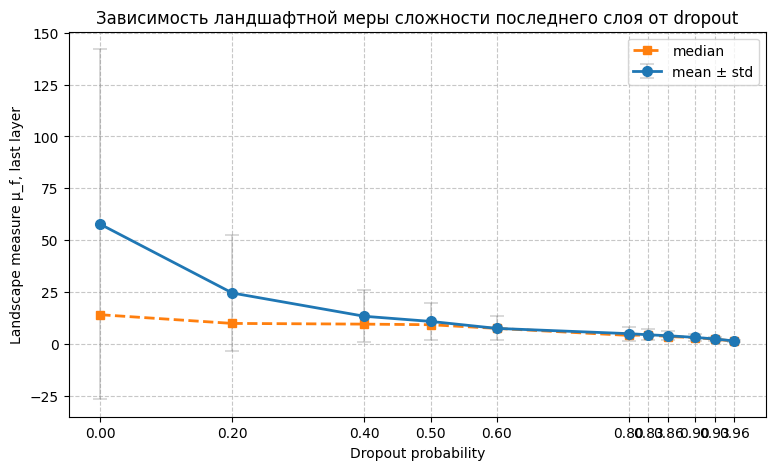


Итоговые значения:
Dropout 0.0: μ_f = 57.667190, std = 84.386198, median = 14.032083
Dropout 0.2: μ_f = 24.496623, std = 28.057415, median = 9.832747
Dropout 0.4: μ_f = 13.275838, std = 12.606999, median = 9.493482
Dropout 0.5: μ_f = 10.808709, std = 8.944891, median = 9.203749
Dropout 0.6: μ_f = 7.441124, std = 5.782703, median = 7.441891
Dropout 0.8: μ_f = 4.900498, std = 3.394362, median = 4.052095
Dropout 0.83: μ_f = 4.352657, std = 2.734936, median = 4.321021
Dropout 0.86: μ_f = 3.892307, std = 2.062795, median = 3.486874
Dropout 0.9: μ_f = 3.098514, std = 1.533555, median = 3.018644
Dropout 0.93: μ_f = 2.367774, std = 0.973369, median = 2.219585
Dropout 0.96: μ_f = 1.358791, std = 0.443120, median = 1.314810


In [25]:
plt.figure(figsize=(9, 5))

line = plt.errorbar(
  dropout_probs_landscape,
  mu_values,
  yerr=mu_stds,
  fmt='o-',
  capsize=5,
  linewidth=2,
  markersize=7,
  label='mean ± std',
  ecolor='gray',
  elinewidth=1.2,
  capthick=1.2
)

for barlinecol in line[2]:
  barlinecol.set_alpha(0.35)

for capline in line[1]:
  capline.set_alpha(0.35)

plt.plot(
  dropout_probs_landscape,
  mu_medians,
  's--',
  linewidth=2,
  markersize=6,
  label='median'
)

plt.xlabel('Dropout probability')
plt.ylabel('Landscape measure μ_f, last layer')
plt.title('Зависимость ландшафтной меры сложности последнего слоя от dropout')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(dropout_probs_landscape)
plt.legend()
plt.savefig("first_method_dropout.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nИтоговые значения:")
for p, mu, std, med in zip(dropout_probs_landscape, mu_values, mu_stds, mu_medians):
  print(f"Dropout {p}: μ_f = {mu:.6f}, std = {std:.6f}, median = {med:.6f}")

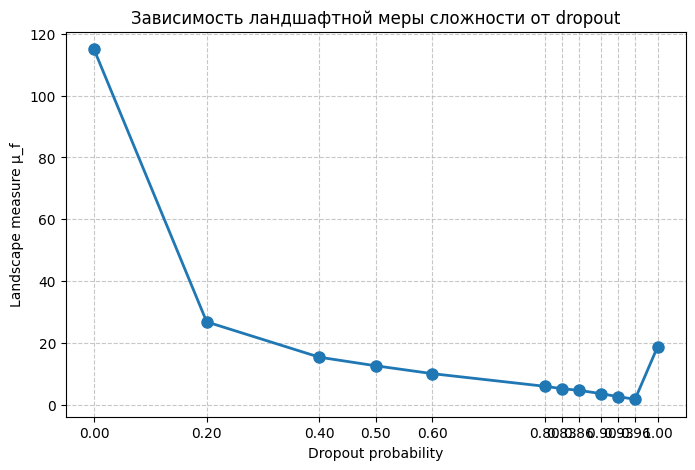


Итоговые значения:
Dropout 0.0: μ_f = 114.998728
Dropout 0.2: μ_f = 26.779319
Dropout 0.4: μ_f = 15.347326
Dropout 0.5: μ_f = 12.572733
Dropout 0.6: μ_f = 10.038119
Dropout 0.8: μ_f = 5.936622
Dropout 0.83: μ_f = 5.179094
Dropout 0.86: μ_f = 4.636907
Dropout 0.9: μ_f = 3.553158
Dropout 0.93: μ_f = 2.575987
Dropout 0.96: μ_f = 1.755857
Dropout 1.0: μ_f = 18.742151


In [14]:
plt.figure(figsize=(8, 5))
plt.plot(dropout_probs, mu_values, 'o-', linewidth=2, markersize=8)
plt.xlabel('Dropout probability')
plt.ylabel('Landscape measure μ_f')
plt.title('Зависимость ландшафтной меры сложности от dropout')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(dropout_probs)
plt.show()

# Вывод численных значений
print("\nИтоговые значения:")
for p, mu in zip(dropout_probs, mu_values):
    print(f"Dropout {p}: μ_f = {mu:.6f}")

In [16]:

class TinyModel(nn.Module):
  def __init__(self, dropout_prob=0.0):
    super().__init__()
    self.conv1 = nn.Conv2d(3, 4, 3, stride=2)
    self.relu1 = nn.ReLU()
    self.conv2 = nn.Conv2d(4, 8, 3, stride=2)
    self.relu2 = nn.ReLU()
    self.pool = nn.AdaptiveAvgPool2d((1, 1))
    self.flat = nn.Flatten()
    self.drop = nn.Dropout(dropout_prob)
    self.lin = nn.Linear(8, 10)

  def forward(self, x):
    x = self.relu1(self.conv1(x))
    x = self.relu2(self.conv2(x))
    x = self.pool(x)
    x = self.flat(x)
    x = self.drop(x)
    return self.lin(x)


def count_parameters(model):
  return sum(p.numel() for p in model.parameters() if p.requires_grad)

_tmp_model = TinyModel().to(device)
print("Число параметров TinyModel для прямого Гессиана:", count_parameters(_tmp_model))

Число параметров TinyModel для прямого Гессиана: 498


In [17]:
def _flatten_or_zero(tensors, params):
  flat_parts = []
  for tensor, param in zip(tensors, params):
    if tensor is None:
      flat_parts.append(torch.zeros_like(param).reshape(-1))
    else:
      flat_parts.append(tensor.reshape(-1))
  return torch.cat(flat_parts)


def compute_single_hessian_direct(model, x, y, params, criterion):
  model.eval()

  outputs = model(x)
  loss = criterion(outputs, y)

  grads = torch.autograd.grad(
    loss,
    params,
    create_graph=True,
    retain_graph=True,
    allow_unused=True
  )

  grad_flat = _flatten_or_zero(grads, params)

  rows = []
  for grad_i in grad_flat:
    second_grads = torch.autograd.grad(
      grad_i,
      params,
      retain_graph=True,
      allow_unused=True
    )
    row = _flatten_or_zero(second_grads, params)
    rows.append(row)

  H = torch.stack(rows).detach().cpu()
  H = 0.5 * (H + H.T)
  return H


def spectral_norm_symmetric(A):
  A = 0.5 * (A + A.T)
  eigvals = torch.linalg.eigvalsh(A)
  return eigvals.abs().max().item()


def compute_mu_direct(model, loader, device):
  model.eval()
  criterion = nn.CrossEntropyLoss(reduction="sum")
  params = [p for p in model.parameters() if p.requires_grad]

  hessians = []

  for x, y in loader:
    x = x.to(device)
    y = y.to(device)

    H = compute_single_hessian_direct(model, x, y, params, criterion)
    hessians.append(H)

  H_mean = torch.stack(hessians, dim=0).mean(dim=0)

  norms = []
  for H in hessians:
    diff = H - H_mean
    norm_value = spectral_norm_symmetric(diff)
    norms.append(norm_value)

  norms = np.array(norms)

  return {
    "mean": float(norms.mean()),
    "std": float(norms.std()),
    "median": float(np.median(norms)),
    "values": norms
  }


In [18]:
def train_tiny_model(model, train_loader, val_loader=None, epochs=25, lr=1e-3, weight_decay=1e-4):
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

  for epoch in range(epochs):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in train_loader:
      x = x.to(device)
      y = y.to(device)

      optimizer.zero_grad()
      logits = model(x)
      loss = criterion(logits, y)
      loss.backward()
      optimizer.step()

      total_loss += loss.item() * x.size(0)
      correct += (logits.argmax(dim=1) == y).sum().item()
      total += y.size(0)

    if (epoch + 1) % 5 == 0 or epoch == 0:
      print(f"epoch={epoch + 1}, loss={total_loss / total:.4f}, acc={correct / total:.4f}")


In [19]:

def make_fixed_direct_loaders(dataset, num_subsets=5, subset_size=30, base_seed=2026):
  loaders = []

  for k in range(num_subsets):
    generator = torch.Generator()
    generator.manual_seed(base_seed + k)

    indices = torch.randperm(len(dataset), generator=generator)[:subset_size]
    subset = Subset(dataset, indices)

    loader = DataLoader(
      subset,
      batch_size=1,
      shuffle=False,
      num_workers=0
    )

    loaders.append(loader)

  return loaders

In [22]:
dropout_probs_direct = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

direct_loaders = make_fixed_direct_loaders(
  dataset=val_dataset,
  num_subsets=5,
  subset_size=30,
  base_seed=2026
)

direct_mu_values = []
direct_mu_stds = []
direct_mu_medians = []

for p in dropout_probs_direct:
  print("=" * 60)
  print(f"dropout = {p}")
  print("=" * 60)

  set_seed(42)

  model = TinyModel(dropout_prob=p).to(device)

  train_tiny_model(
    model=model,
    train_loader=trainloader,
    val_loader=valloader,
    epochs=25,
    lr=1e-3,
    weight_decay=1e-4
  )

  subset_means = []
  subset_stds = []
  subset_medians = []

  for loader_id, loader in enumerate(direct_loaders):
    print(f"subset {loader_id + 1}/{len(direct_loaders)}")

    result = compute_mu_direct(
      model=model,
      loader=loader,
      device=device
    )

    subset_means.append(result["mean"])
    subset_stds.append(result["std"])
    subset_medians.append(result["median"])

    print(
      f"  mean={result['mean']:.6f}, "
      f"std={result['std']:.6f}, "
      f"median={result['median']:.6f}"
    )

  direct_mu_values.append(float(np.mean(subset_means)))
  direct_mu_stds.append(float(np.std(subset_means)))
  direct_mu_medians.append(float(np.median(subset_medians)))

  print(
    f"RESULT dropout={p}: "
    f"mu={direct_mu_values[-1]:.6f}, "
    f"std={direct_mu_stds[-1]:.6f}, "
    f"median={direct_mu_medians[-1]:.6f}"
  )

dropout = 0.0
epoch=1, loss=2.1656, acc=0.1792
epoch=5, loss=1.8999, acc=0.2991
epoch=10, loss=1.7928, acc=0.3429
epoch=15, loss=1.7437, acc=0.3626
epoch=20, loss=1.7067, acc=0.3760
epoch=25, loss=1.6796, acc=0.3854
subset 1/5
  mean=67.325772, std=52.935906, median=46.269608
subset 2/5
  mean=52.241746, std=33.135911, median=37.463615
subset 3/5
  mean=66.812848, std=34.287599, median=52.726736
subset 4/5
  mean=73.774063, std=49.184398, median=51.139639
subset 5/5
  mean=71.175426, std=39.988355, median=52.360554
RESULT dropout=0.0: mu=66.265971, std=7.464252, median=51.139639
dropout = 0.1
epoch=1, loss=2.1801, acc=0.1707
epoch=5, loss=1.9406, acc=0.2738
epoch=10, loss=1.8856, acc=0.2960
epoch=15, loss=1.8487, acc=0.3094
epoch=20, loss=1.8217, acc=0.3184
epoch=25, loss=1.7990, acc=0.3258
subset 1/5
  mean=17.403285, std=13.458933, median=12.871803
subset 2/5
  mean=14.333293, std=7.965491, median=10.517324
subset 3/5
  mean=19.262345, std=11.248489, median=14.620956
subset 4/5
  mea

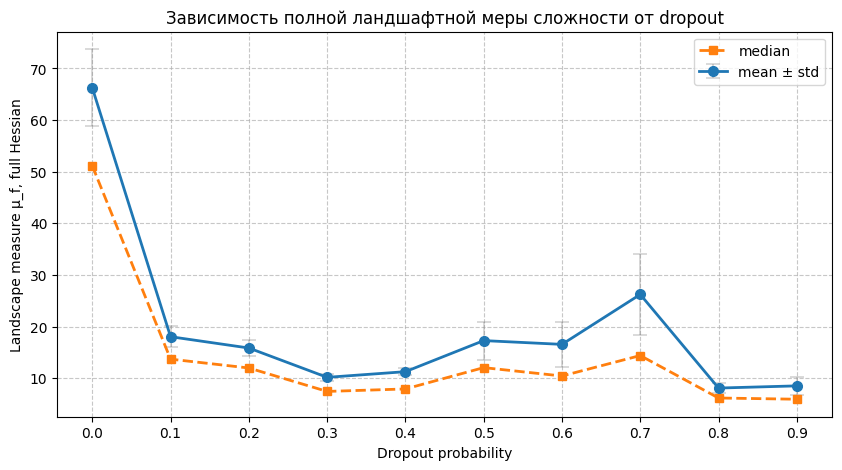


Итоговые значения:
Dropout 0.0: μ_f = 66.265971, std = 7.464252, median = 51.139639
Dropout 0.1: μ_f = 18.028536, std = 2.025207, median = 13.680099
Dropout 0.2: μ_f = 15.837224, std = 1.501699, median = 11.966897
Dropout 0.3: μ_f = 10.156060, std = 0.659967, median = 7.424776
Dropout 0.4: μ_f = 11.253081, std = 0.708454, median = 7.904715
Dropout 0.5: μ_f = 17.273916, std = 3.682446, median = 12.038124
Dropout 0.6: μ_f = 16.542942, std = 4.404266, median = 10.415489
Dropout 0.7: μ_f = 26.219450, std = 7.897981, median = 14.378122
Dropout 0.8: μ_f = 8.077818, std = 0.952405, median = 6.152191
Dropout 0.9: μ_f = 8.502406, std = 1.694276, median = 5.914933


In [26]:
plt.figure(figsize=(10, 5))

line = plt.errorbar(
  dropout_probs_direct,
  direct_mu_values,
  yerr=direct_mu_stds,
  fmt='o-',
  capsize=5,
  linewidth=2,
  markersize=7,
  label='mean ± std',
  ecolor='gray',
  elinewidth=1.2,
  capthick=1.2
)

for barlinecol in line[2]:
  barlinecol.set_alpha(0.35)

for capline in line[1]:
  capline.set_alpha(0.35)

plt.plot(
  dropout_probs_direct,
  direct_mu_medians,
  's--',
  linewidth=2,
  markersize=6,
  label='median'
)

plt.xlabel('Dropout probability')
plt.ylabel('Landscape measure μ_f, full Hessian')
plt.title('Зависимость полной ландшафтной меры сложности от dropout')
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(dropout_probs_direct)
plt.legend()
plt.savefig("second_method_dropout.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nИтоговые значения:")
for p, mu, std, med in zip(
  dropout_probs_direct,
  direct_mu_values,
  direct_mu_stds,
  direct_mu_medians
):
  print(f"Dropout {p}: μ_f = {mu:.6f}, std = {std:.6f}, median = {med:.6f}")



### 1. Вычислительные препятствия для прямого расчёта

Для используемой свёрточной сети число параметров $P$ составляет порядка $10^5$ (только последний линейный слой содержит около $4 \times 10^4$ скалярных параметров). Прямое вычисление матрицы $\mathbf{H}_i$ требует хранения $P \times P$ элементов ($\approx 1.6 \times 10^9$ чисел), что в формате float32 занимает более 6 ГБ на одну матрицу. Хранение и обработка таких объёмов данных для 150 объектов нереализуемы на доступном оборудовании.

Для преодоления «проклятия размерности» применяются два стандартных приёма, согласующихся с методологией диссертации [1] (раздел 3.4):
- **Сужение пространства параметров** – гессиан вычисляется только по части параметров (в данной работе – параметры последнего линейного слоя);
- **Аппроксимация спектральной нормы с помощью матрично-векторных произведений гессиана (HVP) и степенного метода**.

### 2. Матрично-векторное произведение гессиана (HVP)

Пусть $\ell(\theta)$ – значение функции потерь на одном объекте. HVP – это операция $\mathbf{v} \mapsto \mathbf{H}\mathbf{v}$, реализуемая в PyTorch через двойное автоматическое дифференцирование без материализации матрицы $\mathbf{H}$:

$
\mathbf{g} = \nabla_\theta \ell(\theta), \qquad \mathbf{H}\mathbf{v} = \nabla_\theta (\mathbf{g}^\top \mathbf{v}).
$

Такое вычисление требует памяти, пропорциональной числу параметров и размеру графа промежуточных активаций, а не $O(P^2)$, что делает его практически осуществимым для $P \sim 4 \times 10^4$.

### 3. Степенной метод для спектральной нормы

#### 3.1. Спектральная норма и степенной метод

Для любой симметричной вещественной матрицы $\mathbf{A}$ её спектральная норма $\|\mathbf{A}\|_2$ равна максимальному по модулю собственному значению $\lambda_{\max}(\mathbf{A})$. **Степенной метод** (power iteration) – это классический итеративный алгоритм, который находит $\lambda_{\max}$ и соответствующий собственный вектор, используя **только** операцию умножения матрицы на вектор.

Алгоритм состоит из повторения двух шагов:

1. **Умножение:** $\mathbf{w}_{k+1} = \mathbf{A} \mathbf{v}_k$.
2. **Нормировка:** $\mathbf{v}_{k+1} = \frac{\mathbf{w}_{k+1}}{\|\mathbf{w}_{k+1}\|}$.

Если начальный вектор $\mathbf{v}_0$ имеет ненулевую компоненту вдоль искомого собственного вектора $\mathbf{u}_{\max}$, то последовательность $\mathbf{v}_k$ сходится к $\mathbf{u}_{\max}$ (с точностью до знака), а оценка собственного значения даётся **отношением Рэлея**:

$
\hat{\lambda}_{\max} = \mathbf{v}^\top \mathbf{A} \mathbf{v}.
$

Скорость сходимости определяется отношением $|\lambda_2 / \lambda_1|$, где $\lambda_1 = \lambda_{\max}$, а $\lambda_2$ – второе по модулю собственное значение. 
#### 3.2. Применение к матрице $\Delta\mathbf{H}_i = \mathbf{H}_i - \overline{\mathbf{H}}$

Для вычисления ландшафтной меры нам необходимо для каждого объекта $x_i$ найти $\|\Delta\mathbf{H}_i\|_2$. Поскольку $\Delta\mathbf{H}_i$ симметрична (разность симметричных матриц), мы можем применить к ней степенной метод. Однако мы **не можем** построить саму матрицу $\Delta\mathbf{H}_i$ в явном виде из-за её огромного размера. Вместо этого мы реализуем операцию умножения $\Delta\mathbf{H}_i$ на произвольный вектор $\mathbf{w}$ с помощью **матрично-векторного произведения гессиана (HVP)**.

Действие $\Delta\mathbf{H}_i$ на вектор $\mathbf{w}$ раскладывается на два слагаемых:

$
\Delta\mathbf{H}_i \mathbf{w} = \mathbf{H}_i \mathbf{w} - \overline{\mathbf{H}} \mathbf{w}.
$

- **Первое слагаемое** $\mathbf{H}_i \mathbf{w}$ вычисляется напрямую для текущего объекта $x_i$ с помощью процедуры HVP (двойное дифференцирование в PyTorch). Сложность этой операции линейна по числу параметров $P$ и размеру графа активаций, а память – $O(P)$.
- **Второе слагаемое** $\overline{\mathbf{H}} \mathbf{w}$ представляет собой действие **среднего гессиана** на вектор $\mathbf{w}$. По определению $\overline{\mathbf{H}} = \frac{1}{|D|}\sum_{j=1}^{|D|} \mathbf{H}_j$. Следовательно, $\overline{\mathbf{H}} \mathbf{w} = \frac{1}{|D|}\sum_{j=1}^{|D|} \mathbf{H}_j \mathbf{w}$. Это означает, что для **каждого** вектора $\mathbf{w}$ необходимо просуммировать HVP по **всем** объектам выборки $D$.

#### 3.3. Вычислительная нереализуемость точного подхода

Оценим количество вызовов HVP, требуемое для точного вычисления $\|\Delta\mathbf{H}_i\|_2$ для одного объекта. Пусть $|D| = 150$, число итераций степенного метода $N_{\text{iter}} = 30$.

- На каждой итерации степенного метода требуется вычислить $\Delta\mathbf{H}_i \mathbf{w}$ для текущего вектора $\mathbf{w}$.
- Для этого нужно:
  - Один вызов HVP для объекта $i$ (вычисление $\mathbf{H}_i \mathbf{w}$).
  - $|D| = 150$ вызовов HVP (по одному для каждого объекта $j \in D$) для получения $\overline{\mathbf{H}} \mathbf{w}$.
- Итого **151 вызов HVP на одну итерацию**.
- За 30 итераций: $30 \times 151 = 4530$ вызовов HVP **на один объект**.
- Для всех 150 объектов: $150 \times 4530 = 679\,500$ вызовов HVP.

Каждый вызов HVP включает прямое и обратное распространение через всю сеть (или через анализируемые слои), что даже для $P \approx 40\,000$ занимает заметное время. Почти **700 тысяч** таких вызовов для одной модели делают точный расчёт абсолютно нереализуемым в рамках типичных вычислительных ресурсов.

### 4. Используемое приближение: фиксированный вектор $\mathbf{c}$

Для преодоления вычислительного барьера в работе принято следующее приближение. Действие среднего гессиана на **любой** вектор $\mathbf{w}$ заменяется действием на **один случайный вектор** $\mathbf{v}_0$, вычисленным один раз для всей модели:

$
\overline{\mathbf{H}} \mathbf{w} \approx \overline{\mathbf{H}} \mathbf{v}_0 =: \mathbf{c}, \quad \forall \mathbf{w}.
$

Вектор $\mathbf{c}$ вычисляется до запуска степенного метода для какого-либо объекта путём однократного прохода по всем объектам $x_j \in D$:

$
\mathbf{c} = \frac{1}{|D|} \sum_{j=1}^{|D|} \mathbf{H}_j \mathbf{v}_0.
$

После этого в степенном методе для каждого объекта $i$ действие матрицы разности аппроксимируется как:

$
\Delta\mathbf{H}_i \mathbf{w} \approx \mathbf{H}_i \mathbf{w} - \mathbf{c}.
$

Теперь каждая итерация степенного метода требует **всего одного** вызова HVP (для вычисления $\mathbf{H}_i \mathbf{w}$). Общее число вызовов HVP для одной модели сокращается до:

- 150 вызовов для вычисления $\mathbf{c}$,
- плюс $150 \times 30 = 4500$ вызовов для всех итераций по всем объектам.

Итого около **4650 вызовов HVP** – уменьшение более чем в **100 раз** по сравнению с точным подходом. Это делает вычисление практически осуществимым (время счёта порядка нескольких минут на современном оборудовании).


Замена $\overline{\mathbf{H}}\mathbf{w}$ на фиксированный вектор $\mathbf{c}$ вносит систематическую погрешность в абсолютные значения оценок $\|\Delta\mathbf{H}_i\|_2$. Однако данное смещение **одинаково для всех конфигураций dropout**, поскольку:
- архитектура модели и набор данных $D$ фиксированы,
- вектор $\mathbf{v}_0$ генерируется один раз и используется для всех моделей.

Следовательно, относительные различия между значениями $\mu_f$ для разных dropout сохраняются. Убывающий тренд $\mu_f$ с ростом вероятности dropout, предсказываемый теорией (регуляризация уплощает ландшафт), будет наблюдаться и при использовании приближения. Таким образом, принятое упрощение позволяет провести сравнительный анализ, оставаясь в рамках разумных вычислительных затрат, и является стандартным компромиссом в эмпирических исследованиях гессианов глубоких сетей [1, 48].




на 0.8 до 1 сделать побольше точек + аналитический вывод формулы приближения. почему на 1 излом(сравнить теорию с практикой) обосновать почему через произведение можно считать матрицуц проанаоизировать график. Еще вариант взять прям простую сетку где 100 параметров - гессиан 10000 вполне поместитться в памяти компьютера и явно тогда посчитать ландшафтную меру.

## Простая модель с прямым вычислением ландшафта:

In [20]:
class TinyModel(nn.Module):
  def __init__(self, dropout_prob=0.0):
    super().__init__()
    self.conv1 = nn.Conv2d(3, 2, 3, stride=2)
    self.relu1 = nn.ReLU()
    self.conv2 = nn.Conv2d(2, 2, 3, stride=2)
    self.relu2 = nn.ReLU()
    self.pool = nn.AdaptiveAvgPool2d((1,1))
    self.flat = nn.Flatten()
    self.drop = nn.Dropout(dropout_prob)
    self.lin = nn.Linear(2, 10)

  def forward(self, x):
    x = self.relu1(self.conv1(x))
    x = self.relu2(self.conv2(x))
    x = self.pool(x)
    x = self.flat(x)
    x = self.drop(x)
    return self.lin(x)

In [11]:
from torch.autograd.functional import hessian

In [14]:
def compute_mu_direct(model, loader, device):
  model.eval()
  criterion = nn.CrossEntropyLoss()

  params = [p for p in model.parameters() if p.requires_grad]

  hessians = []

  for x, y in loader:
    x, y = x.to(device), y.to(device)

    # forward
    loss = criterion(model(x), y)

    # первый градиент
    grads = torch.autograd.grad(loss, params, create_graph=True)

    # разворачиваем градиенты в вектор
    grad_flat = torch.cat([g.reshape(-1) for g in grads])

    # строим гессиан построчно
    H_rows = []
    for g_i in grad_flat:
      second_grads = torch.autograd.grad(g_i, params, retain_graph=True)
      row = torch.cat([sg.reshape(-1) for sg in second_grads])
      H_rows.append(row)

    H = torch.stack(H_rows).detach().cpu()
    hessians.append(H)

  # средний гессиан
  H_mean = torch.stack(hessians).mean(dim=0)

  # спектральные нормы
  norms = []
  for H in hessians:
    diff = H - H_mean
    _, S, _ = torch.svd(diff)
    norms.append(S[0].item())

  mu = sum(norms) / len(norms)
  return mu

In [28]:

subset_size = 150
indices = torch.randperm(len(train_dataset))[:subset_size]
subset = Subset(train_dataset, indices)
loader = DataLoader(subset, batch_size=1, shuffle=False)

Dropout 0.0: μ_f = 12.375024
Dropout 0.2: μ_f = 7.230789
Dropout 0.4: μ_f = 6.175075
Dropout 0.6: μ_f = 9.878909
Dropout 0.8: μ_f = 3.651618
Dropout 1.0: μ_f = 1.993029


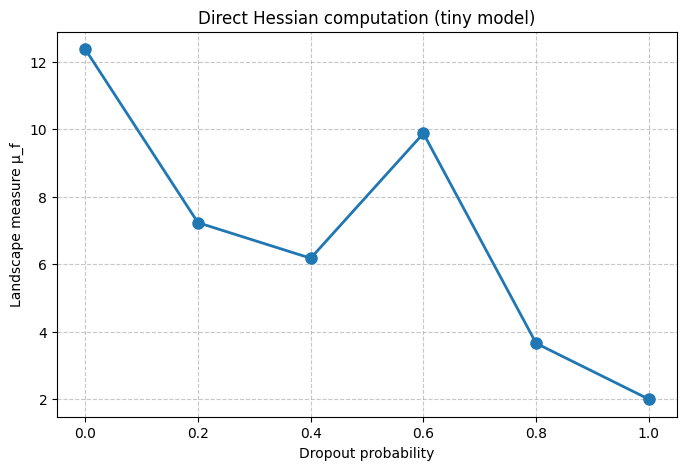

In [29]:
def train_tiny_model(model, train_loader, epochs=15):
  criterion = nn.CrossEntropyLoss()
  optimizer = optim.Adam(model.parameters(), lr=0.001)
  model.train()
  for epoch in range(epochs):
    for x, y in train_loader:
      x, y = x.to(device), y.to(device)
      optimizer.zero_grad()
      loss = criterion(model(x), y)
      loss.backward()
      optimizer.step()


dropout_probs = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
mu_values = []

# Полный загрузчик для обучения (можно использовать только часть данных)
train_loader_full = DataLoader(train_dataset, batch_size=64, shuffle=True)

for p in dropout_probs:
    set_seed(42)                     # одинаковая инициализация
    model = TinyModel(dropout_prob=p).to(device)
    train_tiny_model(model, train_loader_full, epochs=15)
    model.eval()
    mu = compute_mu_direct(model, loader, device)
    mu_values.append(mu)
    print(f"Dropout {p}: μ_f = {mu:.6f}")

# ---------- 6. Построение графика ----------
plt.figure(figsize=(8,5))
plt.plot(dropout_probs, mu_values, 'o-', linewidth=2, markersize=8)
plt.xlabel("Dropout probability")
plt.ylabel("Landscape measure μ_f")
plt.title("Direct Hessian computation (tiny model)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [30]:
dropout_probs = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
num_subsets = 5  # число измерений на точку
subset_size = 50

mu_means = []
mu_stds = []

for p in dropout_probs:
    set_seed(42)
    model = TinyModel(dropout_prob=p).to(device)
    train_tiny_model(model, train_loader_full, epochs=30)
    model.eval()
    
    measurements = []
    for k in range(num_subsets):
        # Генерируем новую случайную подвыборку
        indices = torch.randperm(len(train_dataset))[:subset_size]
        subset = Subset(train_dataset, indices)
        loader = DataLoader(subset, batch_size=1, shuffle=False)
        
        mu = compute_mu_direct(model, loader, device)
        measurements.append(mu)
    
    mean_mu = np.mean(measurements)
    std_mu = np.std(measurements)
    mu_means.append(mean_mu)
    mu_stds.append(std_mu)
    print(f"Dropout {p}: μ_f = {mean_mu:.4f} ± {std_mu:.4f}")

Dropout 0.0: μ_f = 27.7190 ± 8.5942
Dropout 0.2: μ_f = 11.6221 ± 5.0769
Dropout 0.4: μ_f = 24.1992 ± 17.2115
Dropout 0.6: μ_f = 12.5972 ± 8.1623
Dropout 0.8: μ_f = 3.4743 ± 1.4301
Dropout 1.0: μ_f = 1.9751 ± 0.0395


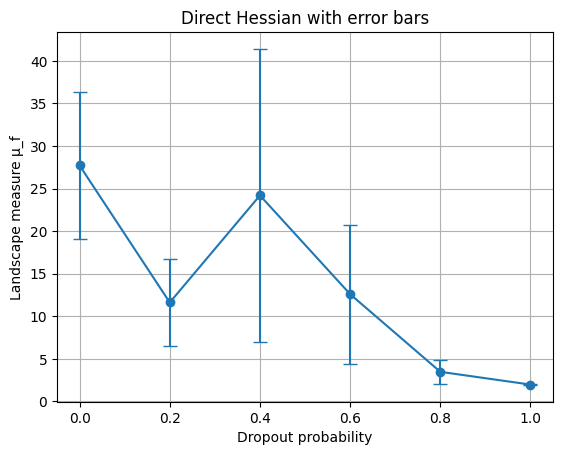

In [32]:
plt.errorbar(dropout_probs, mu_means, yerr=mu_stds, fmt='o-', capsize=5)
plt.xlabel("Dropout probability")
plt.ylabel("Landscape measure μ_f")
plt.title("Direct Hessian with error bars")
plt.grid(True)
plt.show()

-----